### Ciencia de Dados 2026.2 - Aula 7
#### Aluno : João Maria de Araujo Nogueira Junior | Matrícula : 20230041950

# Estatística Inferencial
## Objetivos e Motivações
Essa aula ensionou a decidir se uma diferença observada entre dois grupos, refletem um efeito real ou apenas o acaso de uma amostragem. Para isso, formulamos as hipóteses nula e alternativa para aplicarmos ao teste de permutação e o teste t, e interpretar o p-valor, o nível de significância e os erros tipo I e II, assim distinguindo significância estatística de relevância prática.

## 1. Preparando os dados
Primeiramente, vamos importar as bibliotecas, dependencias e o dataset que irei utilizar (**mtcars**)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="darkgrid", palette="pastel", font="Comic Sans MS") 

A base mtcars tem 32 modelos de carro dos EUA (1973-1974), e só sera utilizado nessa aula o mpg (consumo em milhas por galão, quanto maior mais econômico) e am (câmbio: 0 = automático, 1 = manual).

In [2]:
# Carrega a base e cria o rótulo do câmbio
mtcars = pd.read_csv("../data/mtcars/mtcars.csv")
mtcars["transmission"] = np.where(mtcars["am"].eq(0),"automatico","manual")
mtcars.head()

,model,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb,transmission
0,Mazda RX4,21.0,6,160.0,110,3.90,2.620,16.46,0,1,4,4,manual
1,Mazda RX4 Wag,21.0,6,160.0,110,3.90,2.875,17.02,0,1,4,4,manual
2,Datsun 710,22.8,4,108.0,93,3.85,2.320,18.61,1,1,4,1,manual
3,Hornet 4 Drive,21.4,6,258.0,110,3.08,3.215,19.44,1,0,3,1,automatico
4,Hornet Sportabout,18.7,8,360.0,175,3.15,3.440,17.02,0,0,3,2,automatico


## 2. Diferença Observada

In [3]:
carros_manuais = mtcars[mtcars["transmission"]== "manual"]
carros_automaticos = mtcars[mtcars["transmission"]== "automatico"]

mtcars.groupby("transmission").mpg.agg(["size", "mean", "median", "std"]).round(2)


,size,mean,median,std
transmission,,,,
automatico,19,17.15,17.3,3.83
manual,13,24.39,22.8,6.17


- **Tamanhos desiguais:** são 19 carros automáticos e 13 manuais. como nenhum dos grupos é grande, cada carro influencia bastante a média do seu grupo.
- **Média e mediana diferem um pouco:** nos automáticos os dois valores são quase idênticos (17,15 e 17,3), mas nos manuais a média (24,39) fica acima da mediana (22,8), indicando que alguns carros muito econômicos puxam a média para cima.
- **Manuais variam mais:** o desvio-padrão deles (6,17) é cerca de 60% maior que o dos automáticos (3,83).

In [4]:
mpg_manual = carros_manuais.mpg
mpg_automatic = carros_automaticos.mpg

delta_obs = mpg_manual.mean() - mpg_automatic.mean()

print("Delta Obs (media)= ",round(delta_obs, 2))
print("Delta Obs (mediana)= ",round( mpg_manual.median() - mpg_automatic.median(), 2))

Delta Obs (media)=  7.24
Delta Obs (mediana)=  5.5


Os carros manuais fazem, em média, 7,24 milhas por galão a mais, e a diferença de medianas é menor (5,5 mpg), o que condiz com a assimetria dos manuais, mas nas duas medidas eles aparecem como mais econômicos. O boxplot abaixo mostra a diferença e a dispersão de cada grupo, com cada ponto representando um carro e as linhas tracejadas marcando as médias.

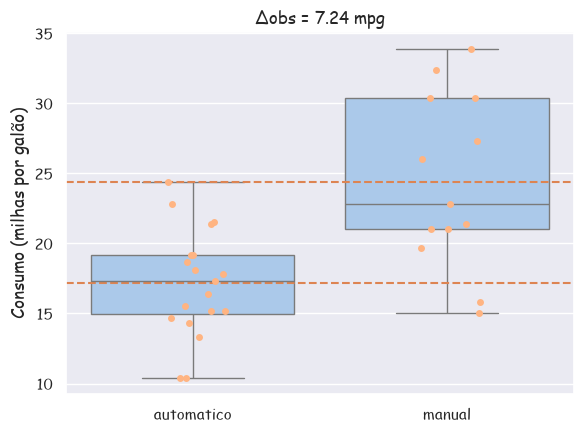

In [5]:
# Boxplot com as observações sobrepostas e as médias de cada grupo
def plot_groups(data, x, y, order, ax, alpha=1, jitter=.15):

    sns.boxplot(data=data, x=x, y=y, order=order, ax=ax,showfliers=False)

    sns.stripplot(data=data, x=x, y=y, order=order, ax=ax, alpha=alpha, jitter=jitter)

fig, ax = plt.subplots(figsize=(6, 4.5))
plot_groups(mtcars, "transmission", "mpg", ["automatico", "manual"], ax)
for mean in [mpg_automatic.mean(), mpg_manual.mean()]:
    ax.axhline(mean, color="#DD8452", linestyle="--")
ax.set(title=f"Δobs = {delta_obs:.2f} mpg", xlabel="",
       ylabel="Consumo (milhas por galão)")
plt.tight_layout()
plt.show()

As caixas do boxplot quase não se sobrepõem, a dos manuais começa perto de onde termina a dos automáticos, e a média dos manuais fica acima de praticamente todos os automáticos, embora ainda haja sobreposição nos extremos. Os manuais parecem mais econômicos, mas isso descreve apenas a amostra e não prova diferença na população, por isso há três motivos para cautela **Natureza estocástica**, **Sensibilidade a valores atípicos**, **Recorte limitado** . A primeira problematica sera abordada no topico a seguir.

## 3. O problema da aleatoriedade

### 3.1 Um pronto-socorro simulado

Abaixo simoulou-se um ano de atendimentos em um pronto-socorro fictício, com todos os dias sorteados da mesma distribuição, de modo que a lua não tem efeito algum. Assim, qualquer diferença entre os grupos é produzida apenas pelo acaso.

In [6]:
# Um ano de atendimentos diários, sem nenhum efeito da lua
rng = np.random.default_rng(2726)

full_moon_days = np.round(np.arange(12) * 29.53 + 14)

er_visits = (
    pd.DataFrame({"day": np.arange(365)})
    .assign(
        visits=rng.poisson(120, size=365),
        full_moon=lambda df: df["day"].isin(full_moon_days),
        moon=lambda df: np.where(df["full_moon"], "Lua cheia", "Demais dias"),
    )
)

Resumo os dois grupos da mesma forma que no mtcars:

In [7]:
# Atendimentos por dia em cada grupo
er_visits.groupby("moon").visits.agg(["size", "mean", "median", "std"]).round(2)

,size,mean,median,std
moon,,,,
Demais dias,353,119.78,119.0,10.94
Lua cheia,12,123.67,121.5,9.36


Na próxima célula, os atendimentos de cada grupo (lua cheia e demais dias) foram separados, como já havia sido feito com manual e automatic, e foi calculado o efeito observado.

In [8]:
vis_demais_dias = er_visits[er_visits["moon"]=="Demais dias"].visits
vis_luas_cheias = er_visits[er_visits["moon"]=="Lua cheia"].visits

moon_obs = vis_luas_cheias.mean() - vis_demais_dias.mean()

print("Delta Obs (media)= ",round(moon_obs, 2))
print("Delta Obs (mediana)= ",round( vis_luas_cheias.median() - vis_demais_dias.median(), 2))

Delta Obs (media)=  3.88
Delta Obs (mediana)=  2.5


aplica-se o bloxplot com o plotgroups da mesma forma que foi feito com o mtcars.

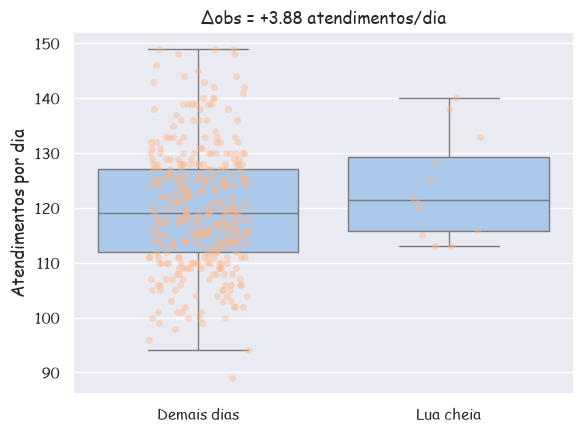

In [9]:
# Atendimentos por grupo
fig, ax = plt.subplots(figsize=(6, 4.5))

plot_groups(
    er_visits, "moon", "visits", ["Demais dias", "Lua cheia"], ax,
    alpha=.4, jitter=.2,
)

ax.set(
    title=f"Δobs = {moon_obs:+.2f} atendimentos/dia",
    xlabel="",
    ylabel="Atendimentos por dia",
)

plt.tight_layout()
plt.show()

Os dias de lua cheia tiveram, em média, cerca de 3,9 atendimentos a mais, o que parece confirmar a crença, apesar de os dados terem sido construídos sem considerar o estado da lua, e o boxplot mostra caixas quase totalmente sobrepostas, ao contrário do mtcars. 
Tendo isso em mente é preciso um procedimento capaz de distinguir os casos sem conhecer a resposta de antemão, considerando não só o tamanho da diferença, mas também quanto ela oscilaria na ausência de efeito.

## 4. Formalizando o acaso

### 4.1 Hipóteses nula e alternativa

Um teste de hipóteses confronta duas proposições sobre a população: 
- hipótese nula (H₀), de que não há efeito e a diferença observada é fruto do acaso.
- hipótese alternativa (H₁), de que existe um efeito real. 

Parte-se de H₀ por ser a única que descreve um cenário preciso, e as alternativas são bilaterais para não escolher o sentido da diferença depois de ver os dados. A lógica é comparavel à de um tribunal, em que H₀ é a presunção de inocência, p-valor ≤ α equivale a “culpado além de dúvida razoável” e não rejeitar H₀ não prova que ela seja verdadeira.

### 4.2 O teste de permutação

Se H₀ for verdadeira, o rótulo “lua cheia” não carrega informação sobre o número de atendimentos, então os rótulos são intercambiáveis. O teste de permutação segue quatro passos: medir o Δobs nos dados reais, embaralhar os rótulos, recalcular o Δ nos dados embaralhados (Δperm) e repetir isso muitas vezes (por exemplo, 10.000) para obter a distribuição nula. No exemplo com seis observações, os valores permanecem nas mesmas posições e só os rótulos trocam de lugar. Há apenas 20 combinações possíveis, mas no pronto-socorro seriam cerca de 9,7 × 10²¹, por isso é sorteada uma amostra grande delas.

Como o procedimento será usado nos dois exemplos anteriores, ele foi colocado em uma função, que a cada repetição embaralha os rótulos e recalcula a diferença de médias. Em seguida, essa função é aplicada aos dados do pronto-socorro.

In [10]:

# Distribuição nula por permutação, aplicada à lua cheia
def permutation_null(values, labels, n_perm=10_000, seed=2026):
    rng = np.random.default_rng(seed)
    null = []
    for _ in range(n_perm):
        shuffled = rng.permutation(labels)
        null.append(values[shuffled].mean() - values[~shuffled].mean())
    return np.array(null)

moon_values = er_visits["visits"].to_numpy()
moon_labels = er_visits["full_moon"].to_numpy()

moon_null = permutation_null(moon_values, moon_labels)

moon_null[:5].round(2)

array([-5.33, -6.46, -2.23, -1.54,  4.49])

Os valores mostram que o acaso pode gerar diferenças positivas ou negativas, até maiores que os 3,9 atendimentos observados. Cada valor de moon_null simula a diferença caso 12 dias aleatórios fossem considerados lua cheia.

A sessão a seguir faz um histograma que reúne as 10.000 diferenças, marcando os limites em $\pm \Delta_{obs}$.

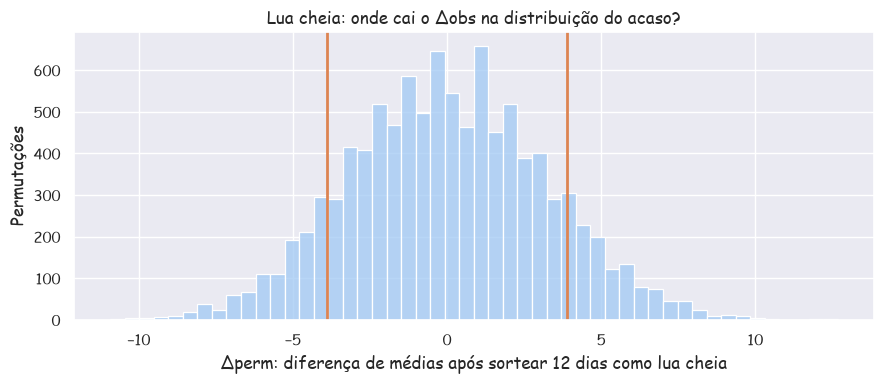

In [11]:
# Distribuição nula da lua cheia e posição do efeito observado
def plot_null(null, obs, title, xlabel):
    fig, ax = plt.subplots(figsize=(9, 4))
    sns.histplot(null, bins=50, color="#A1C9F4", ax=ax)
    for value in [-obs, obs]:
        ax.axvline(value, color="#DD8452", linewidth=2)
    ax.set(title=title, xlabel=xlabel, ylabel="Permutações")
    plt.tight_layout()
    plt.show()

plot_null(
    moon_null,
    moon_obs,
    title="Lua cheia: onde cai o Δobs na distribuição do acaso?",
    xlabel="Δperm: diferença de médias após sortear 12 dias como lua cheia",
)

Neste caso observa-se duas das caracteristicas da distribuição nula :
- Centro em zero, já que nenhum grupo foi favorecida a distribuição se mantem centrada em 0.
- Largura refletindo a oscilação do acaso que ocorre no intervalo de -6 e 6 no caso do dataset artificial.

De todo modo o efeito observado cai numa região povoada da distribuição nula. O código abaixo calcula a proporção de permutações com resultado tão ou mais extremo que o observado:

In [12]:
moon_p = np.mean(np.abs(moon_null) >= abs(moon_obs))

print("p-value: ",moon_p)

p-value:  0.23


### 4.3 P-valor

O p-valor é a probabilidade, supondo $H_0$ verdadeira, de obter um resultado tão extremo ou mais que o observado.

- **Sob $H_0$:** considera-se que não há efeito.
- **Tão ou mais extremo:** considera resultados iguais ou mais distantes de zero ($\geq$).
- **Valor absoluto:** em testes bilaterais, diferenças positivas e negativas contam.

No exemplo, 23% das permutações tiveram diferenças iguais ou maiores que 3,9, indicando que resultados assim não são incomuns mesmo sem efeito real.

O p-valor não deve ser interpretado como a probabilidade de $H_0$ ser verdadeira.

### 4.4 Regra de decisão

Ela utiliza o nível de significância ($\alpha$) para definir o limite que decide se rejeitamos $H_0$. O valor mais comum é 0,05.

- **$p \leq \alpha$:** rejeita-se $H_0$, resultado estatisticamente significativo.
- **$p > \alpha$:** não se rejeita $H_0$, resultado compatível com o acaso. Isso não prova que $H_0$ seja verdadeira.

Com $\alpha = 0{,}05$, aceita-se uma chance de 5% de rejeitar $H_0$ por acaso quando ela é verdadeira.

No exemplo da lua cheia, $p \approx 0{,}23 > 0{,}05$, então não rejeita-se $H_0$.

### 4.5 Permutação no mtcars

Aqui foi repetido o mesmo procedimento de permutação utilizado no dataset sintetico, no dataset do mtcars.

In [13]:
mpg_values = mtcars["mpg"].to_numpy()
mpg_labels = (mtcars["am"] == 1).to_numpy()

mpg_null = permutation_null(mpg_values, mpg_labels)

mpg_p = np.mean(np.abs(mpg_null) >= abs(delta_obs))

print("p-value: ",mpg_p)

p-value:  0.0001


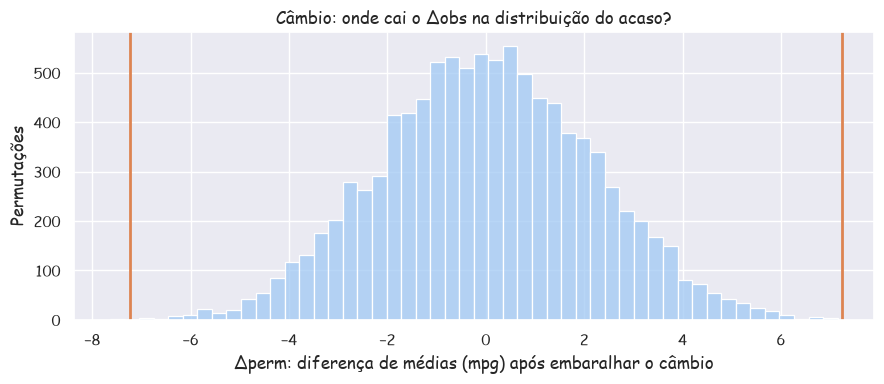

In [14]:
plot_null(mpg_null,delta_obs,title="Câmbio: onde cai o Δobs na distribuição do acaso?",xlabel="Δperm: diferença de médias (mpg) após embaralhar o câmbio")

A distribuição continua centrada em zera, mas agora na escala de mpg. O intervalo de oscilação das diferenças fica entre -4 e 4. Ademais, como o valor p mostrou-se menor que 0.05 , rejeitamos a proposta nula já que uma diferença desse tamanho seria muito rara se o câmbio não importasse.

## 5. O atalho paramétrico

O teste paramétrico calcula o *p* valor usando uma distribuição teórica, sem simulações.

- **Modelo**. Assume uma distribuição conhecida, como a normal.
- **Distribuição nula**. Determina a distribuição da estatística sob a hipótese nula.
- **p valor**. Calcula a probabilidade pela área da cauda.

É mais rápido e pode ter maior poder estatístico, mas depende de premissas que, se violadas, podem gerar resultados enganosos.

### 5.1 O erro padrão

O erro padrão mede a oscilação esperada da diferença entre médias por acaso.

In [15]:
# Largura da distribuição nula do câmbio, medida pela simulação
round(mpg_null.std(), 2)

np.float64(2.16)

A teoria estima essa oscilação sem simulações. A média varia menos que os dados individuais, e a variância da diferença entre duas médias independentes é a soma de suas variâncias.

Sob a hipótese nula, estima se o desvio padrão usando os dados dos dois grupos juntos.

In [16]:
# Largura da distribuição nula do câmbio, prevista pela fórmula
n_manual, n_automatic = len(mpg_manual), len(mpg_automatic)

se_null = mtcars.mpg.std() * np.sqrt(1 / n_manual + 1 / n_automatic)

round(se_null, 2)

np.float64(2.17)

A simulação e a fórmula estimam valores semelhantes para o erro padrão, 2,16 e 2,17 mpg. A curva normal também se ajusta ao histograma das permutações.

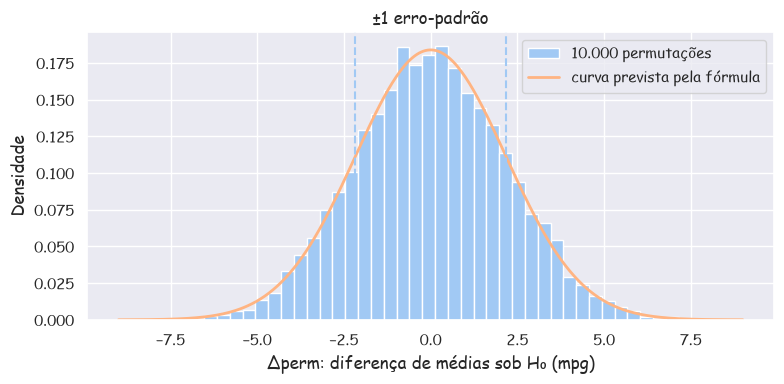

In [17]:
# Histograma das permutações e curva normal prevista pela fórmula
fig, ax = plt.subplots(figsize=(8, 4))

grid = np.linspace(-9, 9, 300)

ax.hist(mpg_null, bins=40, density=True,
        label="10.000 permutações")
ax.plot(grid, stats.norm.pdf(grid, 0, se_null),
         linewidth=2, label="curva prevista pela fórmula")
        
for value in [-se_null, se_null]:
    ax.axvline(value,linestyle="--")

ax.set(title="±1 erro-padrão", xlabel="Δperm: diferença de médias sob H₀ (mpg)",
       ylabel="Densidade")
ax.legend()

plt.tight_layout()
plt.show()

O erro padrão mede a variação esperada pelo acaso. Cerca de 68% das permutações ficam dentro de um erro padrão em torno de zero. 

### 5.2 Desvio padrão e erro padrão

O desvio padrão mede a dispersão dos dados individuais, enquanto o erro padrão mede a variação da estimativa entre amostras. Ao aumentar o tamanho da amostra, o desvio padrão tende a permanecer estável, mas o erro padrão diminui.

In [18]:
# Desvio-padrão dos dados e das médias amostrais, por tamanho de amostra
rng = np.random.default_rng(42)

def sample_summary(n, n_samples=2_000):
    samples = rng.choice(moon_values, size=(n_samples, n))
    return {
        "dp_dos_dados": samples.std(axis=1, ddof=1).mean(),
        "dp_das_medias": samples.mean(axis=1).std(ddof=1),
        "previsto_s_raiz_n": moon_values.std(ddof=1) / np.sqrt(n),
    }

(
    pd.DataFrame({n: sample_summary(n) for n in [10, 40, 160, 640]})
    .T
    .rename_axis("n")
    .round(2)
)

,dp_dos_dados,dp_das_medias,previsto_s_raiz_n
n,,,
10,10.64,3.54,3.45
40,10.81,1.63,1.72
160,10.87,0.89,0.86
640,10.89,0.42,0.43


A tabela mostra que o desvio padrão dos dados permanece próximo de 11 atendimentos, enquanto o erro padrão diminui conforme a amostra aumenta. Os valores observados também se aproximam dos previstos pela fórmula do erro padrão.

### 5.3 A estatística t

A estatística t mede a diferença observada em erros padrão. Neste caso, o resultado é 3,34, indicando que a diferença está a 3,34 erros padrão de zero.



In [19]:
round(delta_obs / se_null, 2) # Efeito observado do câmbio, medido em erros-padrão

np.float64(3.34)

A versão de Welch calcula o erro padrão de cada grupo separadamente, sem exigir variâncias iguais.


In [20]:
# Estatística t de Welch calculada pela fórmula
se_welch = np.sqrt(mpg_manual.var() / n_manual + mpg_automatic.var() / n_automatic)

round(se_welch, 2), round(delta_obs / se_welch, 2)

(np.float64(1.92), np.float64(3.77))


O erro padrão de Welch é 1,92 mpg, elevando a estatística *t* para 3,77. Isso ocorre porque o cálculo considera a variação dentro de cada grupo, sem incluir a diferença entre suas médias na dispersão total.

A distribuição *t* converte a estatística *t* em um *p* valor. Suas caudas são mais pesadas que as da normal para considerar a incerteza da estimativa, ajustada pelos graus de liberdade (*df*). Quanto maior o *df*, mais a distribuição se aproxima da normal.

Os graus de liberdade representam a quantidade de informação disponível para estimar a variabilidade. Amostras maiores fornecem mais graus de liberdade e tornam o teste menos conservador.

In [21]:
# Teste t de Welch no mtcars
mpg_ttest = stats.ttest_ind(mpg_manual, mpg_automatic, equal_var=False)

mpg_ttest

TtestResult(statistic=np.float64(3.767123145144923), pvalue=np.float64(0.0013736383330710362), df=np.float64(18.332251638400464))

In [22]:
# Teste t de Welch na lua cheia
moon_ttest = stats.ttest_ind(vis_luas_cheias, vis_demais_dias, equal_var=False)

moon_ttest

TtestResult(statistic=np.float64(1.4048153658505091), pvalue=np.float64(0.18534026013917088), df=np.float64(12.043510826046889))

O `stats.ttest_ind` realiza o teste de Welch com `equal_var=False` e retorna a estatística *t*, o *p* valor e os graus de liberdade.

No `mtcars`, o *p* valor de 0,0014 indica evidência contra a hipótese nula. Já nos dados da lua cheia, o *p* valor de 0,185 indica que não há evidência suficiente para rejeitá la. Ambos os resultados coincidem com os testes de permutação.

### 5.4 Premissas e limitações do teste *t*

O teste *t* depende de algumas premissas:

- **Independência**. Observações relacionadas, como medições repetidas, exigem outro teste.
- **Normalidade aproximada**. Amostras pequenas e assimétricas podem distorcer o *p* valor.
- **Escala contínua**. Variáveis categóricas ou ordinais exigem outros testes.
- **Variâncias**. Welch aceita variâncias diferentes, ao contrário da versão clássica.

O teste t compara médias, não medianas e é sensível a valores outliers e atipicos.

### 5.5 Um único valor atípico muda a história

Um valor extremo afeta a média e o desvio padrão, alterando a estatística t e o p valor.

In [23]:
# Automáticos com um consumo digitado como 60 mpg
automatic_typo = pd.concat(
    [mpg_automatic, pd.Series([60.])],
    ignore_index=True,
)

def compare(group_a, group_b):
    test = stats.ttest_ind(group_a, group_b, equal_var=False)
    return {
        "dif_medias": group_a.mean() - group_b.mean(),
        "dif_medianas": group_a.median() - group_b.median(),
        "dp_automaticos": group_b.std(),
        "t": test.statistic,
        "p": test.pvalue,
    }


pd.DataFrame({"mtcars original": compare(mpg_manual, mpg_automatic),"+1 automático com 60 mpg": compare(mpg_manual, automatic_typo),}).T.round(4)


,dif_medias,dif_medianas,dp_automaticos,t,p
mtcars original,7.2449,5.50,3.8340,3.7671,0.0014
+1 automático com 60 mpg,5.1023,5.25,10.2831,1.7805,0.0848


Quando adicionei um automático com consumo de 60 mpg, notei que a diferença entre médias caiu de 7,24 para 5,10 mpg, enquanto o desvio padrão dos automáticos sobe de 3,83 para 10,28.

Com isso, a estatística t cai de 3,77 para 1,78 e o p valor sobe de 0,0014 para 0,0848, deixando de indicar significância a 5%. A diferença entre medianas quase não muda, mostrando sua menor sensibilidade a valores extremos.

### 5.6 Permutação e teste *t*

A permutação estima o *p* valor por reamostragem, enquanto o teste *t* usa uma distribuição teórica. A permutação aceita diferentes estatísticas, enquanto o teste *t* compara médias e depende de suas premissas.

In [24]:
# p-valores dos dois métodos nos dois exemplos
pd.DataFrame({"permutação": [mpg_p, moon_p],"teste t (Welch)": [mpg_ttest.pvalue, moon_ttest.pvalue]},index=["mtcars", "Lua cheia"]).round(4)

,permutação,teste t (Welch)
mtcars,0.0001,0.0014
Lua cheia,0.2300,0.1853


Os *p* valores diferem porque os métodos estimam a distribuição nula de formas distintas. No mtcars, são 0,0001 e 0,0014. Nos dados sinteticos da lua cheia, 0,2300 e 0,1853. Apesar das diferenças, ambos levam ao mesma conclusão.

## 6. Armadilhas da decisão

Testes de hipóteses podem levar a erros, multiplicar falsos positivos ou confundir significância estatística com relevância prática.

### 6.1 Dois tipos de erro

- **Tipo I ( $\alpha$)**: Falso positivo, rejeitar uma hipótese nula verdadeira.
- **Tipo II ($\beta$)**: Falso negativo, não detectar um efeito real.
- **Poder estatístico ($1 - \beta$)**: Probabilidade de detectar um efeito existente.

O nível de significância  $\alpha$ controla a taxa de falsos positivos. Já o poder aumenta com o tamanho do efeito e da amostra.

Reduzir  $\alpha$ diminui falsos positivos, mas pode aumentar falsos negativos. Para melhorar o poder sem alterar  $\alpha$, podemos aumentar a amostra, reduzindo o erro padrão.

### 6.2 Muitos testes

Como foi dito anteriormente, o nível de significância de 5% ($\alpha = 0.05$) controla o erro de um teste. Ao realizar vários testes, aumenta a chance de obter falsos positivos. Abaixo, faz-se presente um teste com 20 prontos socorros do dataset sintetico das luas:

In [25]:
rng = np.random.default_rng(7)

hospital_p = stats.ttest_ind(rng.poisson(120, size=(20, 12)),rng.poisson(120, size=(20, 353)),axis=1,equal_var=False,).pvalue

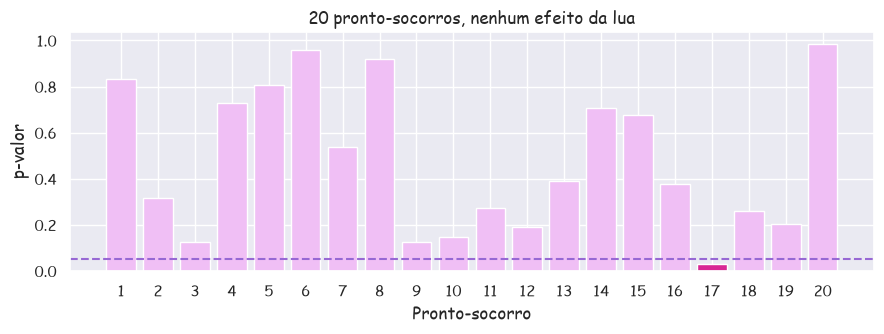

In [30]:
# p-valor de cada pronto-socorro, com destaque para as rejeições
fig, ax = plt.subplots(figsize=(9, 3.5))

ax.bar(np.arange(1, 21),hospital_p,color=np.where(hospital_p <= .05, "#D82694", "#F0BFF5"))
ax.axhline(.05, color="#9768D4", linestyle="--")
ax.set(title="20 pronto-socorros, nenhum efeito da lua",xlabel="Pronto-socorro",ylabel="p-valor",xticks=np.arange(1, 21))

plt.tight_layout()
plt.show()

O gráfico mostra o p-valor de cada pronto-socorro com o limiar de 0.05 . A barra Rosa Choque marca o único pronto-socorro em que o teste rejeitou a hipotese nula.A probabilidade de pelo menos um falso positivo em (k) testes independentes é o complemento da probabilidade de nenhum deles gerar um falso positivo. Uma solução possivel é a correção de Bonferroni e usar $\alpha / k$ como limiar em cada teste. A tabela a seguir compara as abordagens:

In [31]:
# Probabilidade de pelo menos um falso positivo em k testes sem efeito
alpha = .05
pd.DataFrame({"k": [1, 5, 20, 100]}).assign(sem_correcao=lambda df: 1 - (1 - alpha) ** df["k"],bonferroni=lambda df: 1 - (1 - alpha / df["k"]) ** df["k"],).set_index("k").round(3)

,sem_correcao,bonferroni
k,,
1,0.050,0.050
5,0.226,0.049
20,0.642,0.049
100,0.994,0.049


Sem correção, a probabilidade de pelo menos um falso positivo chega a 99,4% em 100 testes. Com Bonferroni, ela permanece próxima de 5%, mas o critério mais rigoroso reduz o poder dos testes.

Esse problema também ocorre quando o analista testa muitas variáveis, subgrupos ou versões de uma análise e relata apenas os resultados significativos.

### 6.3 Significância estatística não é relevância prática

O valor p depende do tamanho da amostra. Para dois grupos com o mesmo tamanho (n) e um efeito fixo (d), a estatística t cresce com raiz quadrada de n. Assim, mesmo uma diferença muito pequena pode se tornar estatisticamente significativa quando a amostra é grande.

In [33]:
# p-valor de um efeito fixo de 0,02 desvio-padrão, por tamanho de grupo
pd.Series({n: 2 * stats.t.sf(.02 * np.sqrt(n / 2), df=2 * n - 2)for n in [100, 1_000, 10_000, 100_000, 1_000_000]},name="p").rename_axis("n por grupo").to_frame()

,p
n por grupo,
100,8.876809e-01
1000,6.547693e-01
10000,1.573148e-01
100000,7.748470e-06
1000000,2.099060e-45


O código calcula o p-valor de um efeito de 0,02 desvio-padrão para diferentes tamanhos de grupo. stats.t.sf calcula a probabilidade na cauda direita da distribuição t.